# Entrega N°1 - Proyecto Final

Para este proyecto seleccionamos el dataset *"Estimation of Obesity Levels Based on Eating Habits and Physical Condition"*, publicado en el repositorio UCI. Reúne 2.111 registros de personas de Colombia, México y Perú, con 17 variables sobre sus datos físicos, hábitos de alimentación, actividad física y antecedentes familiares. Cada persona está clasificada en uno de siete niveles de peso, desde peso insuficiente hasta obesidad tipo III.

### Librerías y Configuraciones

In [1]:
import json
import subprocess
import sys
import tempfile
import time
import warnings
from datetime import datetime
from pathlib import Path

# Instalación automática en Google Colab si falta ucimlrepo
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"])
    from ucimlrepo import fetch_ucirepo

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold,
    train_test_split,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, RobustScaler, StandardScaler

# Configuraciones globales
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

# Semilla para que todo el equipo obtenga los mismos resultados
SEMILLA = 20
np.random.seed(SEMILLA)

print(f"pandas {pd.__version__} | seaborn {sns.__version__} | semilla = {SEMILLA}")


pandas 2.2.3 | seaborn 0.13.2 | semilla = 20


### Importar el Dataset del repositorio de UCI

In [2]:
# Descargar dataset oficial de UCI (id=544)
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544)

# Datos como DataFrames de pandas
X = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets


### Visualización de los datos

In [3]:
dataset = pd.concat([X, y], axis=1)
print("Dimensiones:", dataset.shape)
dataset.head()

Dimensiones: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000,1.620,64.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,0.000,1.000,no,Public_Transportation,Normal_Weight
1,Female,21.000,1.520,56.000,yes,no,3.000,3.000,Sometimes,yes,3.000,yes,3.000,0.000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000,1.800,77.000,yes,no,2.000,3.000,Sometimes,no,2.000,no,2.000,1.000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000,1.800,87.000,no,no,3.000,3.000,Sometimes,no,2.000,no,2.000,0.000,Frequently,Walking,Overweight_Level_I
4,Male,22.000,1.780,89.800,no,no,2.000,1.000,Sometimes,no,2.000,no,0.000,0.000,Sometimes,Public_Transportation,Overweight_Level_II


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [4]:
def resumen(df):
    # Ficha técnica por columna: tipo, nulos, cardinalidad y un ejemplo
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "no_nulos": df.notna().sum(),
        "nulos": df.isna().sum(),
        "%_nulos": (df.isna().mean() * 100).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

In [5]:
resumen(dataset)

,tipo,no_nulos,nulos,%_nulos,valores_unicos,ejemplo
Gender,object,2111,0,0.000,2,Female
Age,float64,2111,0,0.000,1402,21.000
Height,float64,2111,0,0.000,1574,1.620
Weight,float64,2111,0,0.000,1525,64.000
family_history_with_overweight,object,2111,0,0.000,2,yes
FAVC,object,2111,0,0.000,2,no
FCVC,float64,2111,0,0.000,810,2.000
NCP,float64,2111,0,0.000,635,3.000
CAEC,object,2111,0,0.000,4,Sometimes
SMOKE,object,2111,0,0.000,2,no


**¿Qué representa cada característica?**

- *Hábitos de alimentación*

| Variable | Descripción | Valores |
|:---:|:---:|:---:|
| `FAVC` | Consumo frecuente de alimentos calóricos | Sí / No |
| `FCVC` | Consumo de verduras en las comidas | Nunca / A veces / Siempre |
| `NCP` | Comidas principales al día | Entre 1 y 2 / Tres / Más de tres |
| `CAEC` | Consumo de alimentos entre comidas | No / A veces / Frecuentemente / Siempre |
| `CH2O` | Consumo diario de agua | Menos de 1 L / Entre 1 y 2 L / Más de 2 L |
| `CALC` | Consumo de alcohol | No bebo / A veces / Frecuentemente / Siempre |

- *Condición física y estilo de vida*

| Variable | Descripción | Valores |
|:---:|:---:|:---:|
| `SMOKE` | Fuma | Sí / No |
| `SCC` | Controla las calorías que consume | Sí / No |
| `FAF` | Frecuencia de actividad física | No hago / 1–2 días / 2–4 días / 4–5 días por semana |
| `TUE` | Tiempo diario frente a dispositivos electrónicos | 0–2 h / 3–5 h / Más de 5 h |
| `MTRANS` | Medio de transporte habitual | Automóvil / Moto / Bicicleta / Transporte público / Caminar |

### Revisión de duplicados y valores fuera del rango

In [6]:
# Registros duplicadas
n_dup = dataset.duplicated().sum()
print(f"\nRegistros duplicadas: {n_dup} ({n_dup / len(dataset):.1%} del total)")

# Ver cuáles son (keep=False muestra todas las copias, no solo las repetidas)
duplicados = dataset[dataset.duplicated(keep=False)]
print(f"Registros involucrados (originales + copias): {len(duplicados)}")
print("\nClase de los duplicados:")
print(dataset[dataset.duplicated()]["NObeyesdad"].value_counts())

# Valores fuera de rango (coherencia con la encuesta)
rangos = {"Age": (10, 100), "Height": (1.20, 2.20), "Weight": (30, 250),   # rangos fisiológicamente plausibles
          "FCVC": (1, 3), "NCP": (1, 4), "CH2O": (1, 3), "FAF": (0, 3), "TUE": (0, 2)}
print("\nValores fuera del rango esperado:")
for col, (mn, mx) in rangos.items():
    fuera = ((dataset[col] < mn) | (dataset[col] > mx)).sum()
    print(f"  {col:7s} rango [{mn}, {mx}] -> {fuera} fuera de rango")

# Categorías incorrectas en las variables de texto
print("\nCategorías de las variables de texto:")
for col in dataset.select_dtypes(include=["object", "string"]).columns:
    print(f"  {col:32s} {sorted(dataset[col].unique().tolist())}")


Registros duplicadas: 24 (1.1% del total)
Registros involucrados (originales + copias): 33

Clase de los duplicados:
NObeyesdad
Overweight_Level_I     14
Insufficient_Weight     5
Normal_Weight           5
Name: count, dtype: int64

Valores fuera del rango esperado:
  Age     rango [10, 100] -> 0 fuera de rango
  Height  rango [1.2, 2.2] -> 0 fuera de rango
  Weight  rango [30, 250] -> 0 fuera de rango
  FCVC    rango [1, 3] -> 0 fuera de rango
  NCP     rango [1, 4] -> 0 fuera de rango
  CH2O    rango [1, 3] -> 0 fuera de rango
  FAF     rango [0, 3] -> 0 fuera de rango
  TUE     rango [0, 2] -> 0 fuera de rango

Categorías de las variables de texto:
  Gender                           ['Female', 'Male']
  family_history_with_overweight   ['no', 'yes']
  FAVC                             ['no', 'yes']
  CAEC                             ['Always', 'Frequently', 'Sometimes', 'no']
  SMOKE                            ['no', 'yes']
  SCC                              ['no', 'yes']
  CALC    

### Validación de relación entre IMC y Target

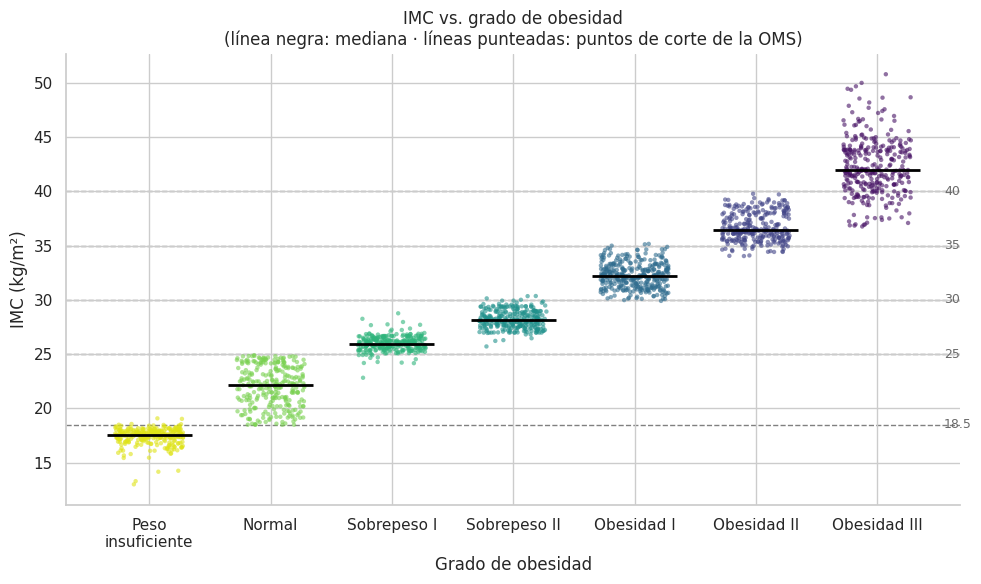

In [7]:
dataset['IMC'] = dataset['Weight'] / dataset['Height']**2

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
colores = plt.cm.viridis_r(np.linspace(0.05, 0.95, 7))

fig, ax = plt.subplots(figsize=(10, 6))
rng = np.random.default_rng(0)
for i, (clase, color) in enumerate(zip(orden, colores)):
    imc = dataset.loc[dataset['NObeyesdad'] == clase, 'IMC']
    x = i + rng.uniform(-0.28, 0.28, len(imc))   # dispersión horizontal para que no se encimen
    ax.scatter(x, imc, s=10, color=color, alpha=0.6, edgecolor='none')
    ax.hlines(imc.median(), i - 0.35, i + 0.35, color='black', linewidth=2)   # mediana

# Puntos de corte de la OMS
for v in [18.5, 25, 30, 35, 40]:
    ax.axhline(v, color='gray', linestyle='--', linewidth=1, zorder=0)
    ax.text(6.55, v, f'{v}', va='center', fontsize=9, color='dimgray')

ax.set_xticks(range(7), etiquetas)
ax.set_xlabel('Grado de obesidad')
ax.set_ylabel('IMC (kg/m²)')
ax.set_title('IMC vs. grado de obesidad\n(línea negra: mediana · líneas punteadas: puntos de corte de la OMS)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

- **Observación**

El IMC aumenta de forma escalonada con cada nivel de obesidad, y casi todos los registros caen dentro de la franja de la OMS que les corresponde (95,2 % de coincidencia). Esto confirma que la variable objetivo se construyó a partir del IMC. Por tanto, si el modelo recibe el peso y la estatura, solo aprendería a recalcular el IMC. Por esta razón se realizó un análisis adicional para evaluar si se debía considerar o no esas características.

### Válidación de balance de clases

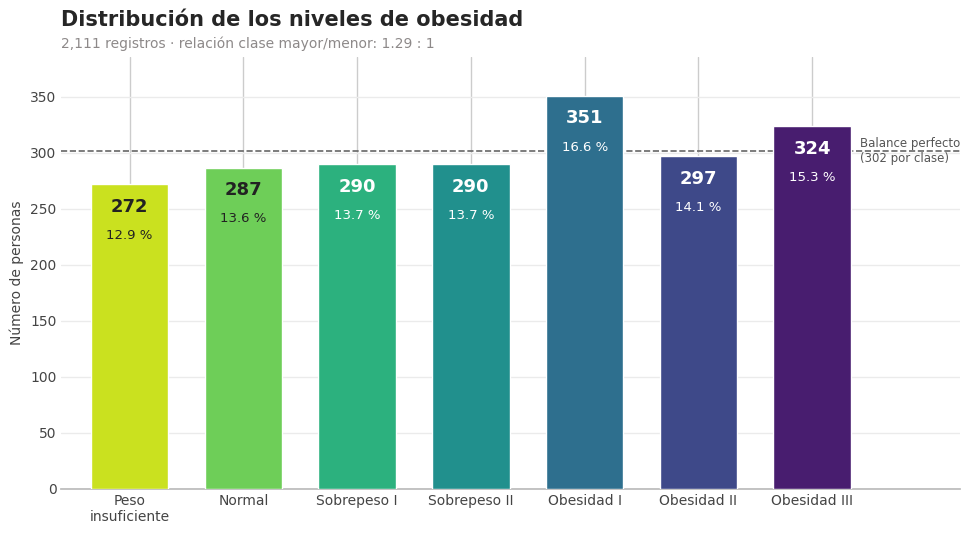

In [8]:
import numpy as np
import matplotlib.pyplot as plt

orden = ['Insufficient_Weight', 'Normal_Weight', 'Overweight_Level_I', 'Overweight_Level_II',
         'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III']
etiquetas = ['Peso\ninsuficiente', 'Normal', 'Sobrepeso I', 'Sobrepeso II',
             'Obesidad I', 'Obesidad II', 'Obesidad III']
conteo = dataset['NObeyesdad'].value_counts().reindex(orden)
porcentaje = conteo / len(dataset) * 100

# Paleta ordenada: de amarillo-verde (peso bajo) a morado (obesidad III)
colores = plt.cm.viridis_r(np.linspace(0.08, 0.92, len(orden)))

fig, ax = plt.subplots(figsize=(10, 5.5))
barras = ax.bar(etiquetas, conteo.values, color=colores, width=0.68, zorder=3)

# Número y porcentaje dentro de cada barra
for barra, n, p, c in zip(barras, conteo.values, porcentaje.values, colores):
    x = barra.get_x() + barra.get_width() / 2
    lum = 0.299*c[0] + 0.587*c[1] + 0.114*c[2]
    texto = '#222222' if lum > 0.55 else 'white'      # texto oscuro en barras claras
    ax.text(x, n - 12, f'{n}', ha='center', va='top', fontsize=13, fontweight='bold', color=texto, zorder=5)
    ax.text(x, n - 40, f'{p:.1f} %', ha='center', va='top', fontsize=9.5, color=texto, zorder=5)

# Línea de balance perfecto (queda detrás de las barras)
ideal = len(dataset) / len(orden)
ax.axhline(ideal, color='#666666', linestyle='--', linewidth=1.2, zorder=2)
ax.text(6.42, ideal, f'Balance perfecto\n({ideal:.0f} por clase)', va='center', fontsize=8.5, color='#555555')

ax.set_title('Distribución de los niveles de obesidad', fontsize=15, fontweight='bold', loc='left', pad=22)
ax.text(0, 1.02, f'{len(dataset):,} registros · relación clase mayor/menor: {conteo.max()/conteo.min():.2f} : 1',
        transform=ax.transAxes, fontsize=10, color="#8D8989")
ax.set_ylabel('Número de personas', fontsize=10, color='#444444')
ax.set_ylim(0, conteo.max() * 1.1)
ax.set_xlim(-0.6, 7.3)
ax.grid(axis='y', color = '#ebebeb', zorder=0)
ax.tick_params(axis='both', length=0, labelsize=10, colors='#444444')
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#bbbbbb')
plt.tight_layout()
plt.show()

El dataset está balanceado. La clase más grande (Obesidad I) tiene apenas 1,29 veces los registros de la más pequeña (Peso insuficiente). Todas quedan cerca del 14,3 % que tendría un balance perfecto, que es la línea punteada de la gráfica.

### Análisis univariado de las variables númericas

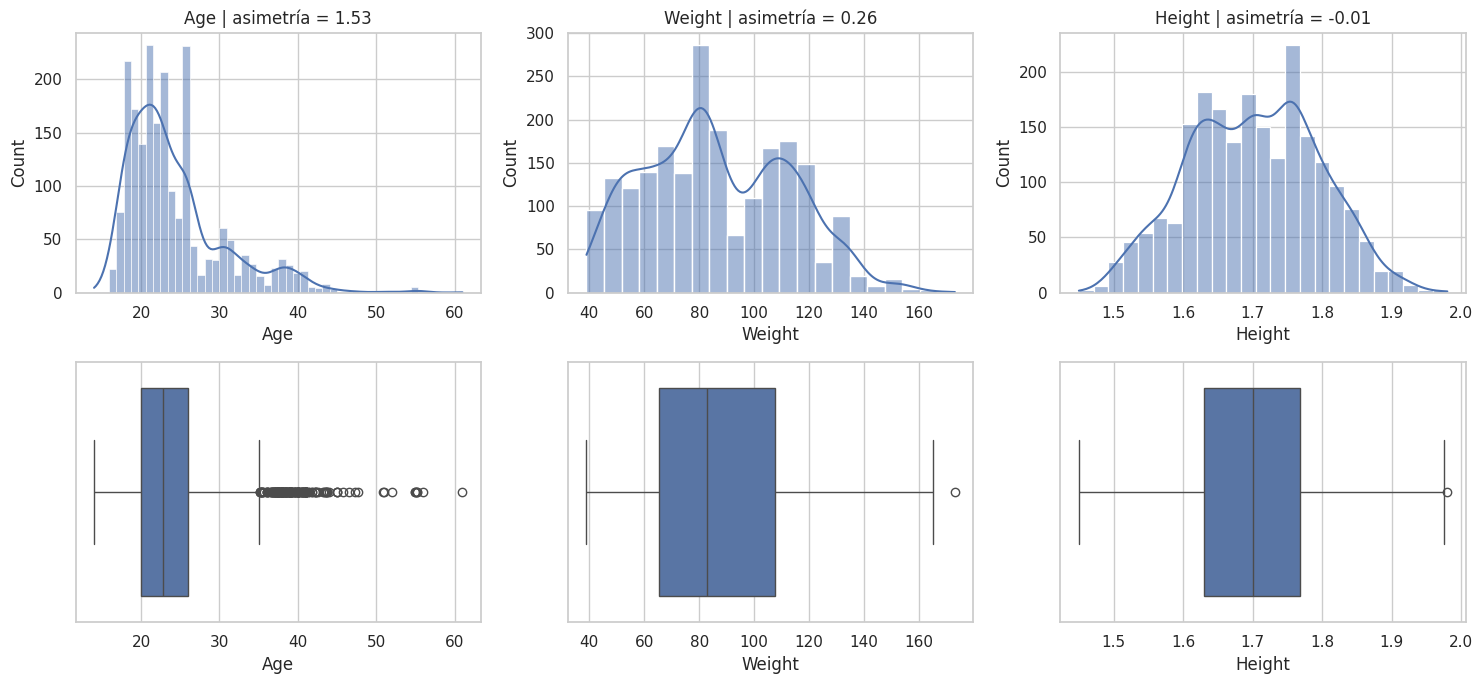

In [9]:
numericas = ["Age", "Weight", "Height"]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for i, col in enumerate(numericas):
    sns.histplot(dataset[col], kde=True, ax=axes[0, i])
    axes[0, i].set_title(f"{col} | asimetría = {dataset[col].skew():.2f}")
    sns.boxplot(x=dataset[col], ax=axes[1, i])
plt.tight_layout(); plt.show()

#### Observaciones

- *Age* tiene asimetría positiva fuerte (1,53). La mayoría de los encuestados son jóvenes: el 76 % tiene 26 años o menos y la mediana es 22,8. La cola se extiende hasta 61 años. El boxplot marca 168 valores atípicos, todos por encima de unos 35 años. No son errores: son personas mayores que simplemente son pocas en la muestra, así que no hay que eliminarlas. Para el informe, esto significa que los resultados representan sobre todo a población joven.
- *Weight* es casi simétrica (0,26), pero tiene varios picos. Eso tiene sentido, porque mezcla personas de 7 niveles de peso distintos. Solo hay un atípico, de 173 kg, y es un valor plausible.
- *Height* es prácticamente normal (−0,01), con una forma de campana centrada en 1,70 m y sin atípicos relevantes.

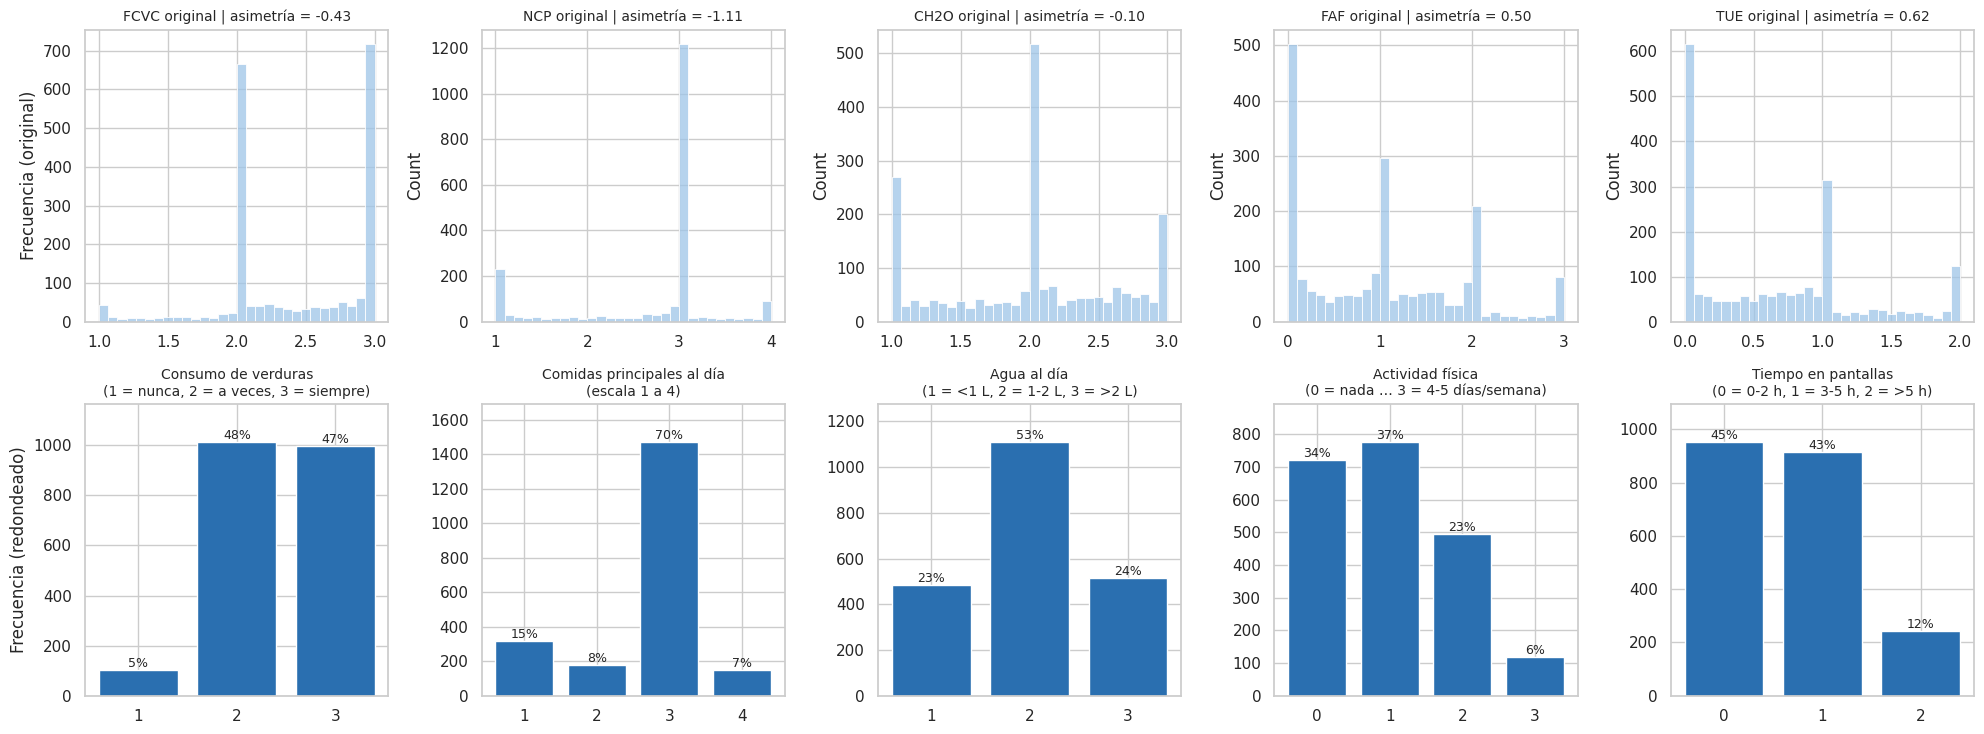

In [10]:
ordinales = {
    "FCVC": "Consumo de verduras\n(1 = nunca, 2 = a veces, 3 = siempre)",
    "NCP":  "Comidas principales al día\n(escala 1 a 4)",
    "CH2O": "Agua al día\n(1 = <1 L, 2 = 1-2 L, 3 = >2 L)",
    "FAF":  "Actividad física\n(0 = nada … 3 = 4-5 días/semana)",
    "TUE":  "Tiempo en pantallas\n(0 = 0-2 h, 1 = 3-5 h, 2 = >5 h)",
}

fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for i, (col, titulo) in enumerate(ordinales.items()):
    # Fila 1: valores originales (con decimales sintéticos)
    sns.histplot(dataset[col], bins=30, ax=axes[0, i], color='#9ec5e8')
    axes[0, i].set_title(f"{col} original | asimetría = {dataset[col].skew():.2f}", fontsize=10)
    axes[0, i].set_xlabel('')

    # Fila 2: valores redondeados a la escala de la encuesta
    conteo = dataset[col].round().astype(int).value_counts().sort_index()
    barras = axes[1, i].bar(conteo.index.astype(str), conteo.values, color='#2a6fb0')
    axes[1, i].bar_label(barras, labels=[f'{v/len(dataset):.0%}' for v in conteo.values], fontsize=9)
    axes[1, i].set_title(titulo, fontsize=10)
    axes[1, i].set_ylim(0, conteo.max() * 1.15)

axes[0, 0].set_ylabel('Frecuencia (original)')
axes[1, 0].set_ylabel('Frecuencia (redondeado)')
plt.tight_layout(); plt.show()


#### Observaciones

- *FCVC, verduras*: casi nadie dice “nunca” (5 %). El resto se reparte entre “a veces” (48 %) y “siempre” (47 %).
NCP, comidas al día: la gran mayoría responde 3 (70 %). Es la variable menos variada, así que probablemente aporte poco para distinguir clases.
- *CH2O, agua*: la distribución es la más equilibrada. La mitad toma entre 1 y 2 litros (53 %).
- *FAF, actividad física*: el 34 % no hace nada de ejercicio y solo el 6 % hace 4 o 5 días por semana. Puede ser de las variables más útiles para el modelo.
- *TUE, pantallas*: la mayoría pasa 0–2 h (45 %) o 3–5 h (43 %) frente a pantallas, y solo el 12 % más de 5 h.


### Análisis bivariado

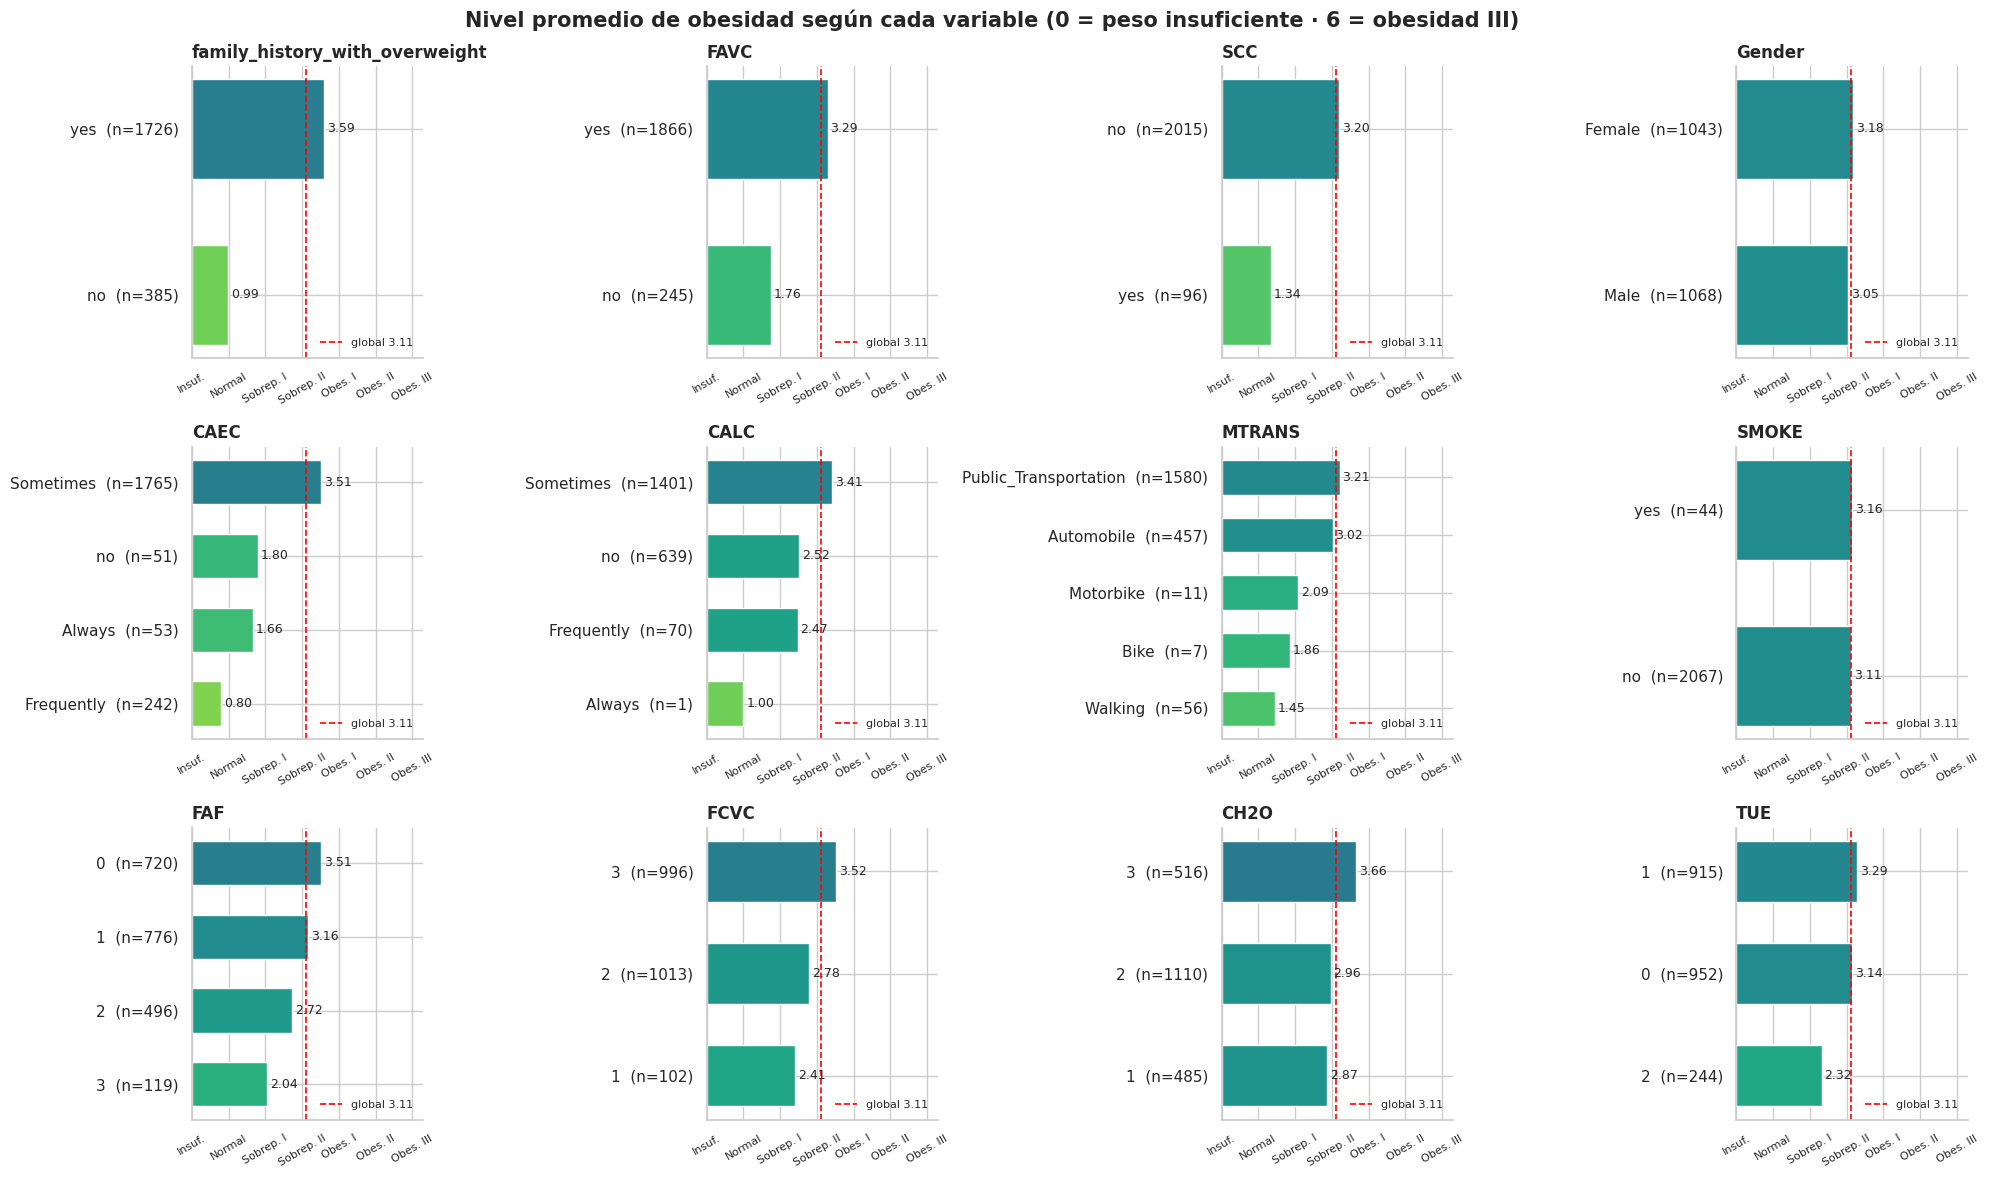

In [11]:
import matplotlib.pyplot as plt

# Codificación ordinal del objetivo: 0 = peso insuficiente ... 6 = obesidad III
niveles = {'Insufficient_Weight': 0, 'Normal_Weight': 1, 'Overweight_Level_I': 2,
           'Overweight_Level_II': 3, 'Obesity_Type_I': 4, 'Obesity_Type_II': 5, 'Obesity_Type_III': 6}
nombres_cortos = ['Insuf.', 'Normal', 'Sobrep. I', 'Sobrep. II', 'Obes. I', 'Obes. II', 'Obes. III']
dataset["nivel"] = dataset["NObeyesdad"].map(niveles)
nivel_global = dataset["nivel"].mean()

dataset_biv = dataset.copy()
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    dataset_biv[col] = dataset_biv[col].round().astype(int)

variables = ["family_history_with_overweight", "FAVC", "SCC", "Gender",
             "CAEC", "CALC", "MTRANS", "SMOKE",
             "FAF", "FCVC", "CH2O", "TUE"]
cmap = plt.cm.viridis_r

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, col in zip(axes.ravel(), variables):
    grupo = dataset_biv.groupby(col)["nivel"].agg(["mean", "size"]).sort_values("mean")
    etiquetas = [f"{c}  (n={n})" for c, n in zip(grupo.index.astype(str), grupo["size"])]
    colores = cmap(0.08 + 0.84 * grupo["mean"].values / 6)   # el color refleja el nivel promedio
    ax.barh(etiquetas, grupo["mean"].values, color=colores, height=0.6)
    for y, v in enumerate(grupo["mean"].values):
        ax.text(v + 0.08, y, f"{v:.2f}", va="center", fontsize=9)
    ax.axvline(nivel_global, color="red", ls="--", lw=1.2, label=f"global {nivel_global:.2f}")
    ax.set_xlim(0, 6.3)
    ax.set_xticks(range(7), nombres_cortos, fontsize=8, rotation=30)
    ax.set_title(col, fontsize=12, fontweight="bold", loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", fontsize=8, frameon=False)

fig.suptitle("Nivel promedio de obesidad según cada variable (0 = peso insuficiente · 6 = obesidad III)",
             fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

- **Observaciones**

La línea roja marca el nivel promedio global (3,11, cercano a Sobrepeso II). Las barras que la superan corresponden a grupos con más obesidad que el promedio, y las que no la alcanzan, a grupos con menos.

- *Antecedentes familiares*: es la variable con mayor diferencia. Quienes no tienen antecedentes promedian 0,99 (peso normal), mientras que quienes sí los tienen llegan a 3,59 (entre sobrepeso II y obesidad I).
- *Hábitos de control*: quienes controlan las calorías que consumen (`SCC`) promedian 1,34 frente a 3,20 de quienes no lo hacen. Algo similar ocurre con el consumo frecuente de comida calórica (`FAVC`): 1,76 sin el hábito y 3,29 con él.
- *Actividad física (`FAF`)*: muestra el patrón más coherente. El nivel baja a medida que aumenta el ejercicio, de 3,51 en quienes no hacen nada a 2,04 en quienes se ejercitan 4–5 días por semana.
- *Transporte (`MTRANS`)*: quienes caminan promedian 1,45, muy por debajo de quienes usan transporte público (3,21) o automóvil (3,02).
- *Relaciones contraintuitivas*: quienes comen verduras "siempre" (`FCVC`) o toman más de 2 L de agua (`CH2O`) tienen mayor nivel de obesidad (3,52 y 3,66), y quienes comen entre comidas "frecuentemente" (`CAEC`) tienen el nivel más bajo (0,80). Esto puede deberse a causalidad inversa (personas con obesidad que cambiaron sus hábitos por recomendación médica) o a artefactos del sobremuestreo sintético.
- *Género*: hombres (3,05) y mujeres (3,18) parecen iguales, pero el promedio esconde una diferencia importante: Obesidad II está compuesta casi solo por hombres y Obesidad III casi solo por mujeres. Esto se confirma con la V de Cramér.
- *Sin diferencia*: fumar (`SMOKE`) y el tiempo frente a pantallas (`TUE`) no muestran diferencias relevantes respecto al promedio.

Fianlmente, se puede notar que también hay categorías con muy pocos registros (`CALC = Always` con n = 1, `Bike` con n = 7 y `Motorbike` con n = 11) no permiten sacar conclusiones confiables.

### V de Cramer

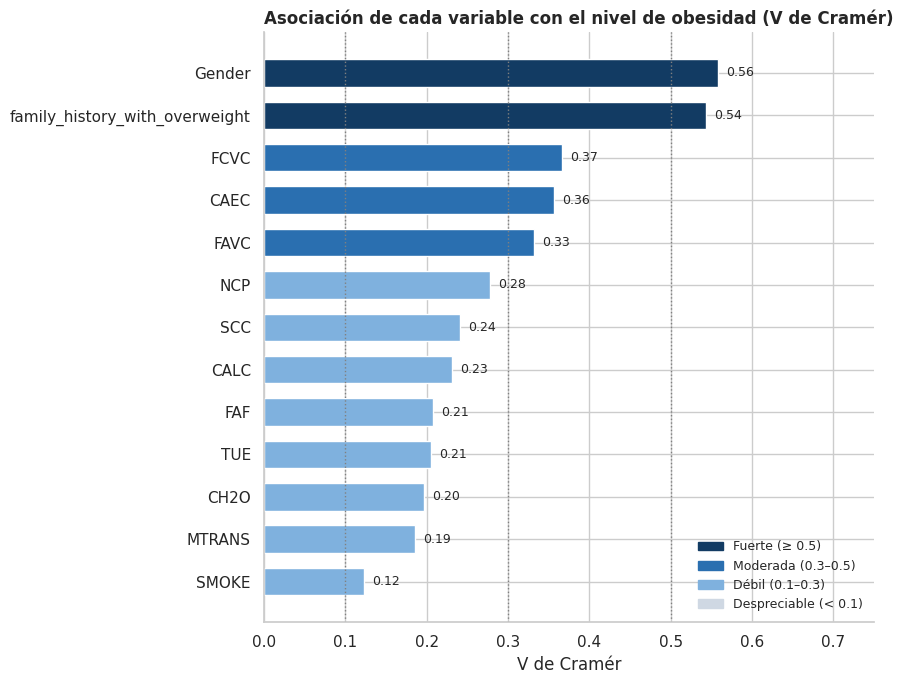

In [12]:
def v_cramer(x, y):
    tabla = pd.crosstab(x, y)
    chi2, p = chi2_contingency(tabla, correction=False)[:2]
    n = tabla.values.sum()
    r, k = tabla.shape
    return np.sqrt((chi2 / n) / (min(r, k) - 1)), p

# Ordinales numéricas redondeadas a su escala
dataset_cat = dataset.copy()
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    dataset_cat[col] = dataset_cat[col].round().astype(int)

cat_vars = [c for c in dataset_cat.select_dtypes(include=["object", "string"]).columns if c != "NObeyesdad"] \
           + ["FCVC", "NCP", "CH2O", "FAF", "TUE"]

resultados = pd.DataFrame(
    [v_cramer(dataset_cat[c], dataset_cat["NObeyesdad"]) for c in cat_vars],
    index=cat_vars, columns=["V de Cramér", "p-valor"]
).sort_values("V de Cramér")

# Gráfica coloreada por fuerza de asociación
def fuerza(v):
    return "Fuerte" if v >= 0.5 else "Moderada" if v >= 0.3 else "Débil" if v >= 0.1 else "Despreciable"
colores_fuerza = {"Fuerte": "#123b63", "Moderada": "#2a6fb0", "Débil": "#7fb1de", "Despreciable": "#cfd8e3"}
colores = [colores_fuerza[fuerza(v)] for v in resultados["V de Cramér"]]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(resultados.index, resultados["V de Cramér"], color=colores, height=0.65)
for y, v in enumerate(resultados["V de Cramér"]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=9)
for umbral in [0.1, 0.3, 0.5]:
    ax.axvline(umbral, color="gray", ls=":", lw=1)
ax.set_xlim(0, 0.75)
ax.set_xlabel("V de Cramér")
ax.set_title("Asociación de cada variable con el nivel de obesidad (V de Cramér)", loc="left", fontweight="bold")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colores_fuerza.values()],
          ["Fuerte (≥ 0.5)", "Moderada (0.3–0.5)", "Débil (0.1–0.3)", "Despreciable (< 0.1)"],
          loc="lower right", frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In [13]:
# Género por clase: evidencia del sesgo (Obesity_II casi solo hombres, Obesity_III casi solo mujeres)
orden_clases = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
                "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
pd.crosstab(dataset["NObeyesdad"], dataset["Gender"]).reindex(orden_clases)

Gender,Female,Male
NObeyesdad,,
Insufficient_Weight,173,99
Normal_Weight,141,146
Overweight_Level_I,145,145
Overweight_Level_II,103,187
Obesity_Type_I,156,195
Obesity_Type_II,2,295
Obesity_Type_III,323,1


- **Observaciones**

Todas las asociaciones son estadísticamente significativas (p ≈ 0), así que lo que importa es su fuerza.

- *Antecedentes familiares* (0,54): es la variable fuerte con sentido real. Casi todas las personas con obesidad tipo I, II y III tienen familiares con sobrepeso.
- *FCVC*, *CAEC* y *FAVC* (0,33 a 0,37): asociación moderada (verduras, comida entre comidas y comida hipercalórica).
- *NCP*, *CALC*, *FAF*, *TUE*, *CH2O*, *MTRANS* y *SMOKE*: asociación débil. Individualmente aportan poco, pero pueden sumar en conjunto.
- ***Gender* (0,56) sale como la variable más fuerte, pero es un sesgo del dataset y no un hallazgo.** Obesidad II tiene 295 hombres y 2 mujeres; Obesidad III tiene 323 mujeres y 1 hombre. Esas clases tienen muy pocas personas reales (unas 11 y 3) y casi todas son sintéticas, generadas con SMOTE a partir de ellas, así que heredaron un género casi puro. En las filas reales el género se reparte parejo en todas las clases.

**Decisión pendiente:** hay que definir qué hacer con *Gender* en el modelo. Las opciones son (1) dejarlo, asumiendo el sesgo y dejándolo documentado; (2) quitarlo del benchmark preventivo; o (3) probar el modelo con y sin *Gender* (y comparar, idealmente también sobre las filas reales) para ver cuánto cambia el rendimiento y la interpretación con SHAP. Por ahora se mantiene en el preventivo, y el riesgo es que el modelo aprenda el atajo "hombre = Obesidad II, mujer = Obesidad III", que infle las métricas y que SHAP muestre el género como un factor de peso que no lo es.

### Codificación de variables categóricas de entrada

In [14]:
data = dataset.copy()

# Binarias
data["Gender"] = data["Gender"].map({"Female": 0, "Male": 1})
for col in ["family_history_with_overweight", "FAVC", "SMOKE", "SCC"]:
    data[col] = data[col].map({"no": 0, "yes": 1})

# Ordinales
for col in ["FCVC", "NCP", "CH2O", "FAF", "TUE"]:
    data[col] = data[col].round().astype(int)

orden_frecuencia = {"no": 0, "Sometimes": 1, "Frequently": 2, "Always": 3}
data["CAEC"] = data["CAEC"].map(orden_frecuencia)
data["CALC"] = data["CALC"].replace("Always", "Frequently")   # "Always" tiene 1 solo registro
data["CALC"] = data["CALC"].map(orden_frecuencia)

# Nominales
data["MTRANS"] = data["MTRANS"].replace({"Bike": "Two_Wheels", "Motorbike": "Two_Wheels"})  # 7 y 11 casos
data = pd.get_dummies(data, columns=["MTRANS"], prefix="MTRANS", dtype=int)

# Target: codificación ordinal de 0 a 6 (peso insuficiente … obesidad III)
niveles = {
    "Insufficient_Weight": 0,
    "Normal_Weight": 1,
    "Overweight_Level_I": 2,
    "Overweight_Level_II": 3,
    "Obesity_Type_I": 4,
    "Obesity_Type_II": 5,
    "Obesity_Type_III": 6,
}
data["NObeyesdad"] = data["NObeyesdad"].map(niveles)
nombres_clases = {v: k for k, v in niveles.items()}   # para volver a nombres al mostrar resultados

# Verificación de la transformación
print(f"Dimensiones: {data.shape}")
print(f"Nulos totales: {data.isna().sum().sum()}")
print(f"Columnas no numéricas: {data.select_dtypes(exclude='number').columns.tolist()}")
print("\nValores únicos por columna (excepto continuas):")
for col in data.columns.drop(["Age", "Height", "Weight"]):
    print(f"  {col:32s} {sorted(data[col].unique().tolist())}")

data.head()

Dimensiones: (2111, 22)
Nulos totales: 0
Columnas no numéricas: []

Valores únicos por columna (excepto continuas):
  Gender                           [0, 1]
  family_history_with_overweight   [0, 1]
  FAVC                             [0, 1]
  FCVC                             [1, 2, 3]
  NCP                              [1, 2, 3, 4]
  CAEC                             [0, 1, 2, 3]
  SMOKE                            [0, 1]
  CH2O                             [1, 2, 3]
  SCC                              [0, 1]
  FAF                              [0, 1, 2, 3]
  TUE                              [0, 1, 2]
  CALC                             [0, 1, 2]
  NObeyesdad                       [0, 1, 2, 3, 4, 5, 6]
  IMC                              [12.998684889724604, 13.291587901701323, 14.160574669617416, 14.25387559306874, 15.432098765432098, 15.457234117286061, 15.665158448270383, 15.792641075006339, 15.822158933586486, 15.8592959374506, 15.905787660342869, 16.027529774529064, 16.088735295769812, 

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,NObeyesdad,IMC,nivel,MTRANS_Automobile,MTRANS_Public_Transportation,MTRANS_Two_Wheels,MTRANS_Walking
0,0,21.000,1.620,64.000,1,0,2,3,1,0,2,0,0,1,0,1,24.387,1,0,1,0,0
1,0,21.000,1.520,56.000,1,0,3,3,1,1,3,1,3,0,1,1,24.238,1,0,1,0,0
2,1,23.000,1.800,77.000,1,0,2,3,1,0,2,0,2,1,2,1,23.765,1,0,1,0,0
3,1,27.000,1.800,87.000,0,0,3,3,1,0,2,0,2,0,2,2,26.852,2,0,0,0,1
4,1,22.000,1.780,89.800,0,0,2,1,1,0,2,0,0,0,1,3,28.342,3,0,1,0,0


- **Observaciones**

Las variables binarias se codificaron como 0/1; las ordinales, respetando su orden; MTRANS con one-hot, agrupando bicicleta y moto por tener pocos casos; y el objetivo de 0 a 6. Las ordinales numéricas se redondearon a la escala original de la encuesta. La codificación se aplica antes de la división porque usa mapeos fijos que no dependen de los datos, por lo que no introduce fuga de información.

### Matriz de Spearman para Variables Numéricas

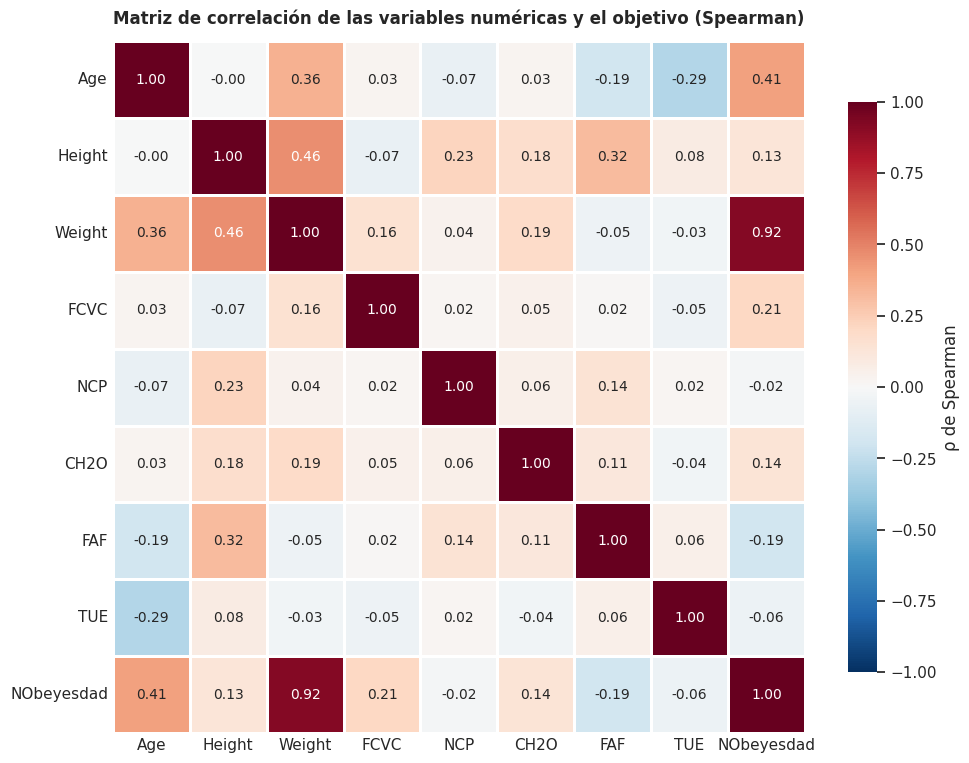

In [15]:
numericas = ["Age", "Height", "Weight", "FCVC", "NCP", "CH2O", "FAF", "TUE", "NObeyesdad"]
corr = data[numericas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=1, linecolor="white", annot_kws={"size": 10},
            cbar_kws={"shrink": 0.8, "label": "ρ de Spearman"}, ax=ax)

ax.set_title("Matriz de correlación de las variables numéricas y el objetivo (Spearman)",
             loc="left", fontweight="bold", fontsize=12, pad=12)
ax.tick_params(length=0)
plt.xticks(rotation=0); plt.yticks(rotation=0)
plt.tight_layout(); plt.show()

### División del Dataset Train / Test

Se eliminan los duplicados y se dividen los datos 80/20 estratificado. Se arman dos conjuntos de variables con las mismas filas:

- **Preventivo (principal):** hábitos, antecedentes, edad y género. Sin peso, estatura ni IMC (fuga de información). *Gender* se mantiene por ahora, pero presenta un sesgo del dataset sintético (ver observaciones de la V de Cramér) y su uso está por decidir.
- **Operativo (referencia):** todas las variables más IMC, para medir el efecto de la fuga.

In [16]:
# Duplicados: se eliminan ANTES de dividir, para que una misma persona no quede en entrenamiento y en prueba
sin_dup = ~dataset.duplicated()
print(f"Duplicados eliminados: {(~sin_dup).sum()} ({len(dataset)} -> {sin_dup.sum()} registros)")
data_u = data[sin_dup]

# Nunca son variables de entrada: el target y 'nivel' (copia numérica del target, creada para graficar)
excluir = ["NObeyesdad", "nivel"]

# Benchmark preventivo (principal): hábitos, antecedentes, edad y género. Sin Weight, Height ni IMC (fuga: la clase se calcula con ellos)
# OJO: Gender tiene sesgo por el SMOTE (Obesity_II casi todo hombres, Obesity_III casi todo mujeres). Se mantiene por ahora; decisión pendiente
X_prev = data_u.drop(columns=excluir + ["Weight", "Height", "IMC"])
# Benchmark operativo (referencia): todas las variables + IMC, para medir el efecto de la fuga
X_oper = data_u.drop(columns=excluir)
y = data_u["NObeyesdad"]

# Un único split para ambos benchmarks (mismas filas, misma semilla)
idx_train, idx_test = train_test_split(
    y.index, test_size=0.2, stratify=y, random_state=SEMILLA)

X_train, X_test = X_prev.loc[idx_train], X_prev.loc[idx_test]               # preventivo
X_train_oper, X_test_oper = X_oper.loc[idx_train], X_oper.loc[idx_test]     # operativo
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# Verificación anti-fuga
assert not {"NObeyesdad", "nivel", "Weight", "Height", "IMC"} & set(X_train.columns), "Fuga en el preventivo"
assert not {"NObeyesdad", "nivel"} & set(X_train_oper.columns), "El target está en las variables de entrada"

print("\nPreventivo -> Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Operativo  -> Entrenamiento:", X_train_oper.shape, "| Prueba:", X_test_oper.shape)

# Proporción de cada clase en total, entrenamiento y prueba
proporciones = pd.DataFrame({
    "Total (%)": y.value_counts(normalize=True),
    "Entrenamiento (%)": y_train.value_counts(normalize=True),
    "Prueba (%)": y_test.value_counts(normalize=True),
}).sort_index()
proporciones.index = proporciones.index.map(nombres_clases)
print((proporciones * 100).round(1))

Duplicados eliminados: 24 (2111 -> 2087 registros)

Preventivo -> Entrenamiento: (1669, 17) | Prueba: (418, 17)
Operativo  -> Entrenamiento: (1669, 20) | Prueba: (418, 20)
                     Total (%)  Entrenamiento (%)  Prueba (%)
NObeyesdad                                                   
Insufficient_Weight     12.800             12.800      12.700
Normal_Weight           13.500             13.500      13.600
Overweight_Level_I      13.200             13.200      13.200
Overweight_Level_II     13.900             13.900      13.900
Obesity_Type_I          16.800             16.800      16.700
Obesity_Type_II         14.200             14.200      14.400
Obesity_Type_III        15.500             15.500      15.600


---
## Preprocesamiento P1: Escalado Robusto (`RobustScaler`)

Como primera metodología de preprocesamiento (**P1 · Línea Base**), conservamos las 17 variables limpias del benchmark preventivo y aplicamos **Escalado Robusto**:

$$x_{\text{rob}} = \frac{x - Q_2(x)}{Q_3(x) - Q_1(x)}$$

- **Por qué se elige:** en el EDA se observó que `Age` presenta asimetría positiva fuerte ($1,53$) y $168$ valores altos ($> 35$ años) que son adultos reales y no deben eliminarse. A diferencia de `StandardScaler` (sensible a la media) o `MinMaxScaler` (que comprime a la mayoría joven en un rango estrecho), `RobustScaler` centra con la **mediana ($Q_2$)** y escala con el **rango intercuartílico ($\text{IQR} = Q_3 - Q_1$)**.
- **Cero fuga de información:** `RobustScaler` se encapsula en un `Pipeline` para que $Q_1, Q_2, Q_3$ se calculen **exclusivamente sobre el pliegue de entrenamiento** en cada partición de validación cruzada.
- **Papel en la matriz $3 \times 3$:** homogeniza magnitudes para modelos sensibles a escala (como el MLP del equipo) y establece el espacio original de referencia (17 variables sin rotar ni expandir) para los ensambles de árboles (`Random Forest` y `XGBoost`).

In [17]:
def crear_preprocesador_p1():
    """Preprocesamiento P1: Escalado Robusto in-fold sobre el espacio base de variables."""
    return Pipeline([
        ("scaler", RobustScaler()),
    ])


# Diagnóstico demostrativo ajustado SOLO con X_train (sin tocar X_test)
p1_demo = crear_preprocesador_p1()
X_train_p1 = pd.DataFrame(
    p1_demo.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)

# Tabla resumen antes vs. después en las variables de mayor rango (para el artículo IEEE)
cols_escala = ["Age", "FCVC", "NCP", "CH2O", "FAF", "TUE", "CAEC", "CALC"]
resumen_p1 = pd.DataFrame({
    "Antes · Mediana": X_train[cols_escala].median(),
    "Antes · IQR": X_train[cols_escala].quantile(0.75) - X_train[cols_escala].quantile(0.25),
    "Antes · [Min, Max]": [f"[{X_train[c].min():.1f}, {X_train[c].max():.1f}]" for c in cols_escala],
    "P1 · Mediana": X_train_p1[cols_escala].median().round(3),
    "P1 · IQR": (X_train_p1[cols_escala].quantile(0.75) - X_train_p1[cols_escala].quantile(0.25)).round(3),
    "P1 · [Min, Max]": [f"[{X_train_p1[c].min():.2f}, {X_train_p1[c].max():.2f}]" for c in cols_escala],
})
resumen_p1


,Antes · Mediana,Antes · IQR,"Antes · [Min, Max]",P1 · Mediana,P1 · IQR,"P1 · [Min, Max]"
Age,22.883,6.052,"[14.0, 61.0]",0.000,1.000,"[-1.47, 6.30]"
FCVC,2.000,1.000,"[1.0, 3.0]",0.000,1.000,"[-1.00, 1.00]"
NCP,3.000,0.000,"[1.0, 4.0]",0.000,0.000,"[-2.00, 1.00]"
CH2O,2.000,0.000,"[1.0, 3.0]",0.000,0.000,"[-1.00, 1.00]"
FAF,1.000,2.000,"[0.0, 3.0]",0.000,1.000,"[-0.50, 1.00]"
TUE,1.000,1.000,"[0.0, 2.0]",0.000,1.000,"[-1.00, 1.00]"
CAEC,1.000,0.000,"[0.0, 3.0]",0.000,0.000,"[-1.00, 2.00]"
CALC,1.000,1.000,"[0.0, 2.0]",0.000,1.000,"[-1.00, 1.00]"


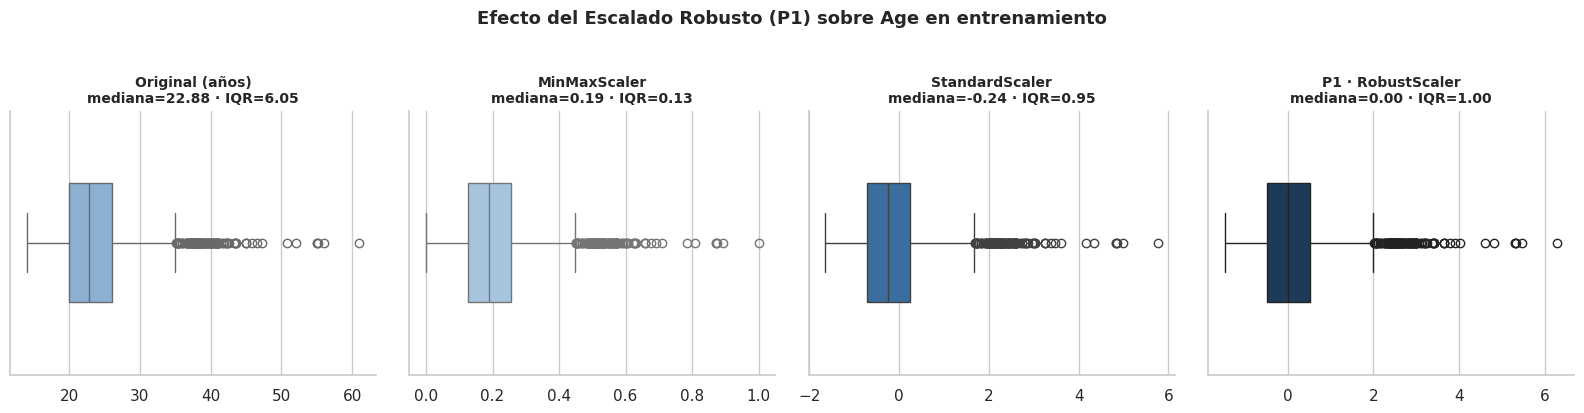

In [18]:
# Comparación visual en Age (ajustado solo en X_train, estilo Semana 1 del curso)
age_col = X_train[["Age"]]
comparacion_age = pd.DataFrame({
    "Original (años)": age_col["Age"].values,
    "MinMaxScaler": MinMaxScaler().fit_transform(age_col).ravel(),
    "StandardScaler": StandardScaler().fit_transform(age_col).ravel(),
    "P1 · RobustScaler": RobustScaler().fit_transform(age_col).ravel(),
})

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
colores_esc = ["#7fb1de", "#9ec5e8", "#2a6fb0", "#123b63"]

for ax, (nombre, serie), color in zip(axes, comparacion_age.items(), colores_esc):
    sns.boxplot(x=serie, ax=ax, color=color, width=0.45)
    iqr_val = np.percentile(serie, 75) - np.percentile(serie, 25)
    ax.set_title(f"{nombre}\nmediana={np.median(serie):.2f} · IQR={iqr_val:.2f}", fontsize=10, fontweight="bold")
    ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Efecto del Escalado Robusto (P1) sobre Age en entrenamiento", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


---
## Modelo M1: Clasificador Random Forest (`RandomForestClassifier`)

**Random Forest** es un método de ensamble por **Bagging** (*Bootstrap Aggregating*) que entrena en paralelo $T$ árboles de decisión independientes sobre muestras con reemplazo y selecciona en cada nodo un subconjunto aleatorio de $m$ características (típicamente $m = \sqrt{d}$), decidiendo la clase final por promedio de probabilidades de clase.

### Control de complejidad y sobreajuste
Un árbol individual sin restricciones crece hasta dejar hojas puras ($\text{Gini} = 0$), memorizando el ruido y las interpolaciones de SMOTE. Siguiendo los criterios vistos en clase, regulamos la capacidad del bosque ajustando `max_depth`, `min_samples_leaf`, `max_leaf_nodes`, `max_features` y `n_estimators` mediante validación cruzada estratificada de 5 pliegues (`F1-macro`).

### Complejidad computacional teórica (Big-O)
Sea $n$ el número de muestras de entrenamiento, $d$ el número de variables tras el preprocesamiento, $m \le d$ las variables evaluadas por nodo, $T$ el número de árboles y $h$ la profundidad máxima alcanzada:

| Fase | Complejidad Big-O | Explicación |
| :--- | :---: | :--- |
| **Entrenamiento (tiempo)** | $\mathcal{O}(T \cdot m \cdot n \log_2 n)$ | Ordenamiento y evaluación de cortes de Gini en $T$ árboles independientes (paralelizable en CPU). |
| **Inferencia por muestra (tiempo)** | $\mathcal{O}(T \cdot h)$ | Recorrido raíz → hoja de longitud $\le h$ en cada uno de los $T$ árboles. |
| **Memoria / Espacio** | $\mathcal{O}(T \cdot N_{\text{nodos}})$ | Almacena la estructura completa de nodos y probabilidades de las 7 clases por hoja (en el peor caso $N_{\text{nodos}} = \mathcal{O}(2^h)$). |


In [19]:
cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

param_dist_rf = {
    "clf__n_estimators": [150, 250, 350],
    "clf__max_depth": [6, 8, 10, 12, 16, None],
    "clf__min_samples_leaf": [1, 2, 4, 6],
    "clf__max_leaf_nodes": [None, 40, 80, 120],
    "clf__max_features": ["sqrt", "log2", 0.5],
}


def entrenar_evaluar_rf(nombre_prep, preprocesador, X_tr, y_tr, X_te, y_te, nombre_bench="Preventivo"):
    """Ajusta Random Forest con 5-Fold CV sobre un preprocesador y mide métricas + complejidad."""
    pipe = Pipeline([
        ("prep", clone(preprocesador)),
        ("clf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)),
    ])

    busqueda = RandomizedSearchCV(
        estimator=pipe,
        param_distributions=param_dist_rf,
        n_iter=30,
        scoring="f1_macro",
        cv=cv_5,
        random_state=SEMILLA,
        n_jobs=-1,
        return_train_score=True,
    )
    busqueda.fit(X_tr, y_tr)
    mejor_pipe = busqueda.best_estimator_

    # Medición limpia del tiempo de entrenamiento del mejor pipeline
    pipe_tiempo = clone(mejor_pipe)
    t0 = time.perf_counter()
    pipe_tiempo.fit(X_tr, y_tr)
    tiempo_fit_s = time.perf_counter() - t0

    # Medición limpia de latencia de inferencia en X_test
    t0 = time.perf_counter()
    y_pred_te = pipe_tiempo.predict(X_te)
    latencia_total_ms = (time.perf_counter() - t0) * 1000
    latencia_por_muestra_ms = latencia_total_ms / len(X_te)

    y_pred_tr = pipe_tiempo.predict(X_tr)

    # Tamaño en disco (.pkl) y estructura del bosque
    with tempfile.NamedTemporaryFile(suffix=".pkl", delete=False) as tmp:
        ruta_tmp = Path(tmp.name)
    joblib.dump(pipe_tiempo, ruta_tmp)
    tamano_kb = ruta_tmp.stat().st_size / 1024
    ruta_tmp.unlink(missing_ok=True)

    bosque = pipe_tiempo.named_steps["clf"]
    total_nodos = int(sum(est.tree_.node_count for est in bosque.estimators_))
    prof_media = float(np.mean([est.tree_.max_depth for est in bosque.estimators_]))

    idx_best = busqueda.best_index_
    cv_mean = busqueda.cv_results_["mean_test_score"][idx_best]
    cv_std = busqueda.cv_results_["std_test_score"][idx_best]

    train_acc = accuracy_score(y_tr, y_pred_tr)
    test_acc = accuracy_score(y_te, y_pred_te)

    registro = {
        "Modelo": "M1_RandomForest",
        "Preprocesamiento": nombre_prep,
        "Benchmark": nombre_bench,
        "CV F1-macro": f"{cv_mean:.4f} ± {cv_std:.4f}",
        "Train Accuracy": round(train_acc, 4),
        "Test Accuracy": round(test_acc, 4),
        "Brecha Train-Test": round(train_acc - test_acc, 4),
        "Test F1-macro": round(f1_score(y_te, y_pred_te, average="macro"), 4),
        "Tiempo fit (s)": round(tiempo_fit_s, 4),
        "Latencia test (ms)": round(latencia_total_ms, 3),
        "ms / muestra": round(latencia_por_muestra_ms, 4),
        "Total nodos": total_nodos,
        "Prof. media": round(prof_media, 1),
        "Tamaño (.pkl KB)": round(tamano_kb, 1),
        "Mejores hiperparámetros": busqueda.best_params_,
    }
    return pipe_tiempo, registro


# Diccionario de preprocesadores: hoy corre con P1; aquí se agregan P2 y P3 del equipo
preprocesadores_rf = {
    "P1_RobustScaler": crear_preprocesador_p1(),
    # "P2_Habitos_YeoJohnson": crear_preprocesador_p2(),
    # "P3_Robust_PCA95": crear_preprocesador_p3(),
}

modelos_rf = {}
resultados_rf = []

for nombre_p, prep in preprocesadores_rf.items():
    modelo_ajustado, fila_res = entrenar_evaluar_rf(
        nombre_p, prep, X_train, y_train, X_test, y_test, nombre_bench="Preventivo"
    )
    modelos_rf[nombre_p] = modelo_ajustado
    resultados_rf.append(fila_res)

tabla_rf = pd.DataFrame(resultados_rf)
print("Mejores hiperparámetros en P1:", tabla_rf.loc[0, "Mejores hiperparámetros"])
tabla_rf.drop(columns=["Mejores hiperparámetros"])


Mejores hiperparámetros en P1: {'clf__n_estimators': 350, 'clf__min_samples_leaf': 2, 'clf__max_leaf_nodes': 120, 'clf__max_features': 'sqrt', 'clf__max_depth': None}


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Total nodos,Prof. media,Tamaño (.pkl KB)
0,M1_RandomForest,P1_RobustScaler,Preventivo,0.7749 ± 0.0143,0.889,0.789,0.100,0.782,0.703,76.862,0.184,83650,14.400,"9,955.700"


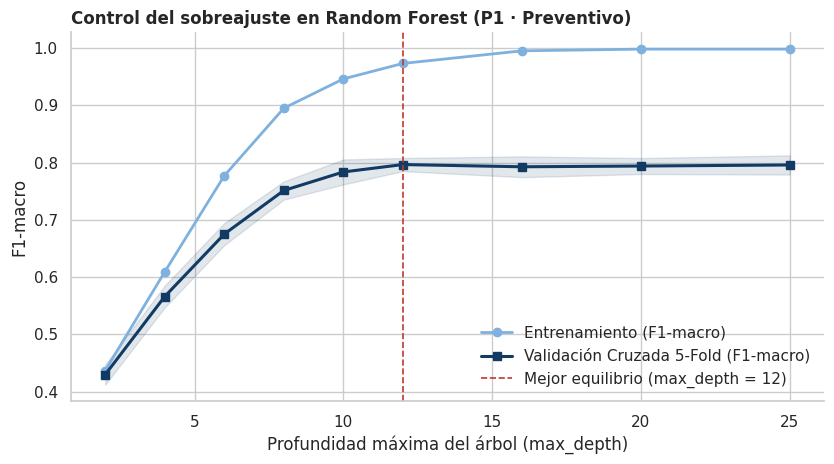

In [20]:
# Curva de validación según max_depth (evidencia visual del control de sobreajuste)
profundidades = [2, 4, 6, 8, 10, 12, 16, 20, 25]
pipe_curva = Pipeline([
    ("prep", crear_preprocesador_p1()),
    ("clf", RandomForestClassifier(n_estimators=250, random_state=SEMILLA, n_jobs=-1)),
])

tr_scores, val_scores = validation_curve(
    pipe_curva, X_train, y_train,
    param_name="clf__max_depth",
    param_range=profundidades,
    cv=cv_5,
    scoring="f1_macro",
    n_jobs=-1,
)

tr_mean, tr_std = tr_scores.mean(axis=1), tr_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(profundidades, tr_mean, marker="o", color="#7fb1de", lw=2, label="Entrenamiento (F1-macro)")
ax.plot(profundidades, val_mean, marker="s", color="#123b63", lw=2.2, label="Validación Cruzada 5-Fold (F1-macro)")
ax.fill_between(profundidades, val_mean - val_std, val_mean + val_std, color="#123b63", alpha=0.12)

mejor_d = profundidades[int(np.argmax(val_mean))]
ax.axvline(mejor_d, color="#c0392b", ls="--", lw=1.2, label=f"Mejor equilibrio (max_depth = {mejor_d})")
ax.set_xlabel("Profundidad máxima del árbol (max_depth)")
ax.set_ylabel("F1-macro")
ax.set_title("Control del sobreajuste en Random Forest (P1 · Preventivo)", fontweight="bold", loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


In [21]:
# 1. Ablación de Gender (mide el impacto del sesgo sintético de SMOTE en Obesidad II y III)
modelo_rf_sin_gender, res_sin_gender = entrenar_evaluar_rf(
    "P1_RobustScaler",
    crear_preprocesador_p1(),
    X_train.drop(columns=["Gender"]),
    y_train,
    X_test.drop(columns=["Gender"]),
    y_test,
    nombre_bench="Preventivo (sin Gender)",
)

# 2. Benchmark Operativo de referencia (incluye Weight, Height e IMC -> cuantifica la fuga)
modelo_rf_oper, res_oper = entrenar_evaluar_rf(
    "P1_RobustScaler",
    crear_preprocesador_p1(),
    X_train_oper,
    y_train,
    X_test_oper,
    y_test,
    nombre_bench="Operativo (con Peso/Altura/IMC)",
)

comparacion_controles_rf = pd.DataFrame([
    resultados_rf[0],
    res_sin_gender,
    res_oper,
])

comparacion_controles_rf.drop(columns=["Mejores hiperparámetros"])


,Modelo,Preprocesamiento,Benchmark,CV F1-macro,Train Accuracy,Test Accuracy,Brecha Train-Test,Test F1-macro,Tiempo fit (s),Latencia test (ms),ms / muestra,Total nodos,Prof. media,Tamaño (.pkl KB)
0,M1_RandomForest,P1_RobustScaler,Preventivo,0.7749 ± 0.0143,0.889,0.789,0.100,0.782,0.703,76.862,0.184,83650,14.400,"9,955.700"
1,M1_RandomForest,P1_RobustScaler,Preventivo (sin Gender),0.7375 ± 0.0076,0.874,0.744,0.130,0.735,0.573,55.302,0.132,59750,14.100,"7,115.800"
2,M1_RandomForest,P1_RobustScaler,Operativo (con Peso/Altura/IMC),0.9851 ± 0.0042,0.999,0.986,0.014,0.985,0.906,76.970,0.184,75894,13.300,"9,046.900"


=== Reporte por clase · M1 Random Forest + P1 (Benchmark Preventivo) ===

              precision    recall  f1-score   support

 Peso insuf.      0.807     0.868     0.836        53
      Normal      0.640     0.561     0.598        57
 Sobrepeso I      0.741     0.727     0.734        55
Sobrepeso II      0.760     0.655     0.704        58
  Obesidad I      0.800     0.743     0.770        70
 Obesidad II      0.766     0.983     0.861        60
Obesidad III      0.969     0.969     0.969        65

    accuracy                          0.789       418
   macro avg      0.783     0.787     0.782       418
weighted avg      0.787     0.789     0.785       418



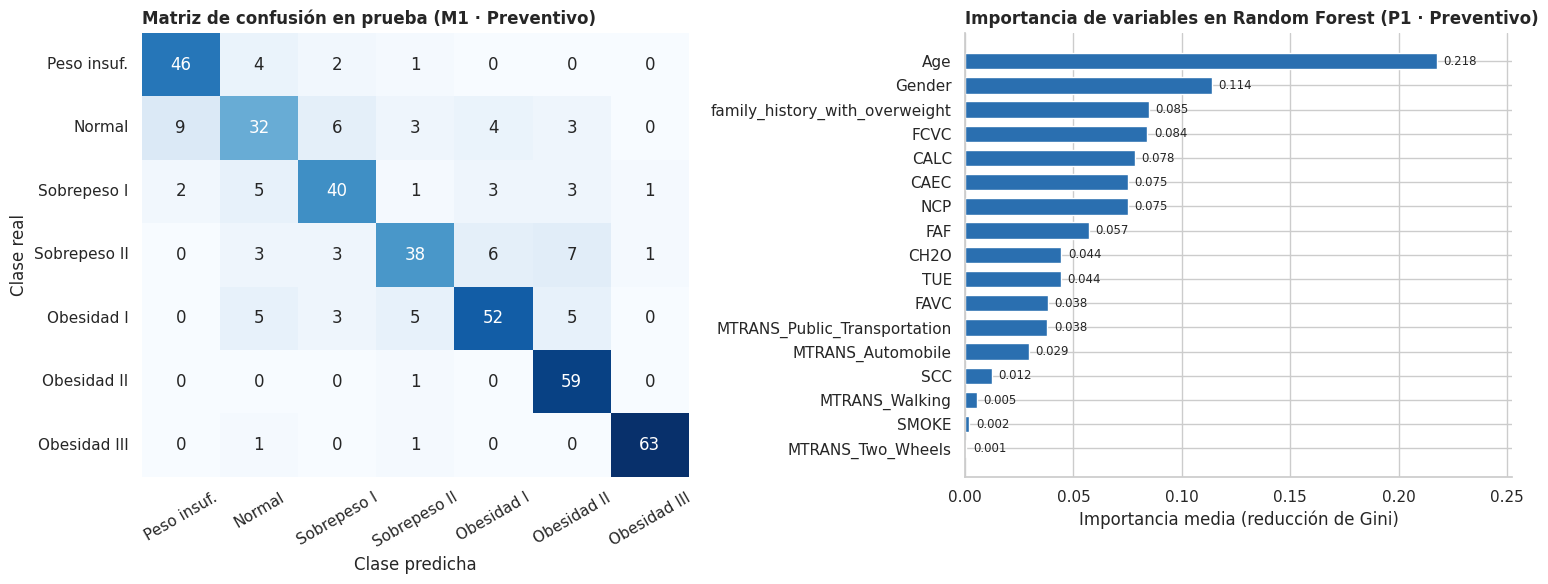

In [22]:
mejor_rf_prev = modelos_rf["P1_RobustScaler"]
y_pred_test_rf = mejor_rf_prev.predict(X_test)

etiquetas_cortas = [
    "Peso insuf.", "Normal", "Sobrepeso I", "Sobrepeso II",
    "Obesidad I", "Obesidad II", "Obesidad III",
]

print("=== Reporte por clase · M1 Random Forest + P1 (Benchmark Preventivo) ===\n")
print(classification_report(y_test, y_pred_test_rf, target_names=etiquetas_cortas, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(15.5, 6))

# Panel 1: Matriz de confusión en prueba
cm = confusion_matrix(y_test, y_pred_test_rf)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=etiquetas_cortas, yticklabels=etiquetas_cortas, ax=axes[0]
)
axes[0].set_title("Matriz de confusión en prueba (M1 · Preventivo)", fontweight="bold", loc="left")
axes[0].set_xlabel("Clase predicha")
axes[0].set_ylabel("Clase real")
axes[0].tick_params(axis="x", rotation=30)
axes[0].tick_params(axis="y", rotation=0)

# Panel 2: Importancia de variables por reducción de impureza de Gini
imp = pd.Series(
    mejor_rf_prev.named_steps["clf"].feature_importances_,
    index=X_train.columns,
).sort_values()

axes[1].barh(imp.index, imp.values, color="#2a6fb0", height=0.68)
for idx_y, val in enumerate(imp.values):
    axes[1].text(val + 0.003, idx_y, f"{val:.3f}", va="center", fontsize=8.5)
axes[1].set_xlim(0, imp.max() * 1.16)
axes[1].set_xlabel("Importancia media (reducción de Gini)")
axes[1].set_title("Importancia de variables en Random Forest (P1 · Preventivo)", fontweight="bold", loc="left")
axes[1].spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


### Guardado Permanente de Pesos y Métricas en Google Drive
Exportamos los *pipelines* entrenados (`.pkl`), la tabla comparativa (`.csv`) y los metadatos (`m1_rf_metricas.json`, compatible con la estructura de despliegue vista en clase) directamente a `Proyecto_Final_Aprendizaje_Automatico/modelos/` en Google Drive.


In [23]:
try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    CARPETA_MODELOS = Path("/content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos")
except ImportError:
    CARPETA_MODELOS = Path("modelos")

CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)

# 1. Guardar pipelines entrenados (.pkl incluye el escalador + el bosque)
for clave_prep, pipe_ent in modelos_rf.items():
    ruta_pkl = CARPETA_MODELOS / f"m1_rf_{clave_prep.lower()}_preventivo.pkl"
    joblib.dump(pipe_ent, ruta_pkl)
    print(f"Guardado: {ruta_pkl} ({ruta_pkl.stat().st_size / 1024:.1f} KB)")

ruta_sin_gender = CARPETA_MODELOS / "m1_rf_p1_sin_gender.pkl"
joblib.dump(modelo_rf_sin_gender, ruta_sin_gender)
print(f"Guardado: {ruta_sin_gender} ({ruta_sin_gender.stat().st_size / 1024:.1f} KB)")

# 2. Guardar tabla comparativa en CSV para consolidar con los compañeros de M2 y M3
tabla_export_rf = pd.concat([tabla_rf, comparacion_controles_rf.iloc[1:]], ignore_index=True)
tabla_export_rf["Mejores hiperparámetros"] = tabla_export_rf["Mejores hiperparámetros"].apply(
    lambda d: json.dumps(d, ensure_ascii=False)
)
ruta_csv = CARPETA_MODELOS / "resultados_m1_rf.csv"
tabla_export_rf.to_csv(ruta_csv, index=False, encoding="utf-8")

# 3. Guardar metadatos para la App de Despliegue (esquema metricas.json de Semana 7)
fila_p1 = tabla_rf.iloc[0]
metricas_export = {
    "algoritmo": "RandomForestClassifier (M1)",
    "preprocesamiento": str(fila_p1["Preprocesamiento"]),
    "benchmark": str(fila_p1["Benchmark"]),
    "accuracy": float(fila_p1["Test Accuracy"]),
    "f1_macro": float(fila_p1["Test F1-macro"]),
    "cv_f1_macro": str(fila_p1["CV F1-macro"]),
    "tiempo_fit_s": float(fila_p1["Tiempo fit (s)"]),
    "ms_por_muestra": float(fila_p1["ms / muestra"]),
    "tamano_kb": float(fila_p1["Tamaño (.pkl KB)"]),
    "hiperparametros": fila_p1["Mejores hiperparámetros"],
    "columnas": list(X_train.columns),
    "clases": {str(k): v for k, v in nombres_clases.items()},
    "rangos": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in X_train.columns},
    "fecha": datetime.now().strftime("%Y-%m-%d %H:%M"),
}
ruta_json = CARPETA_MODELOS / "m1_rf_metricas.json"
ruta_json.write_text(json.dumps(metricas_export, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Tabla CSV y metadatos JSON guardados en: {CARPETA_MODELOS}")


Mounted at /content/drive
Guardado: /content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos/m1_rf_p1_robustscaler_preventivo.pkl (9955.7 KB)
Guardado: /content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos/m1_rf_p1_sin_gender.pkl (7115.8 KB)
Tabla CSV y metadatos JSON guardados en: /content/drive/MyDrive/Proyecto_Final_Aprendizaje_Automatico/modelos
